# Kaggle "Name That LLM" Competition: EXP63
## Prompt-Conditional Relative Attribution & Constrained Set Assignment

- **Experiment ID**: `EXP63_prompt_relative`
- **Research Question**: Does modeling LLM attribution as a prompt-conditional relative comparison problem rather than independent classification improve out-of-fold generalization, and does prompt-level constrained set assignment resolve sibling confusion?
- **Frozen Baseline**: EXP52 Dual-LoRA Kernel (Qwen3-8B 0.60 + Qwen3-14B 0.40, **0.7873 OOF BA**, **0.632 Public LB**)
- **Verdict**: **YELLOW** (Dense $R=18$ Hungarian matching achieves **0.9040 BA** ($+0.1167$), but completely collapses to **$+0.0052$** under realistic sparse $R=2$ test conditions; training-only artifact)
- **Production Status**: **Retain EXP52 as frozen production champion**


In [1]:
# 1. Environment, Imports & Dynamic Path Discovery
import os
import sys
import io
import json
import time
import zlib
import base64
import pathlib
import numpy as np
import pandas as pd
import scipy.special
import scipy.stats
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import balanced_accuracy_score, f1_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from IPython.display import Image, display

# Ensure reproducible figures
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

# Embedded Verified Data (Enables 100% Standalone Execution in Kaggle Kernels)
EMBEDDED_PAYLOAD = {"labels": ["claude-fable-5", "claude-opus-4-6", "claude-opus-4-8", "claude-opus-5", "claude-sonnet-5", "gemini-3.1-pro-preview", "gemini-3.6-flash", "gemini-3.7-flash", "gemini-3.8-flash", "glm-5.3", "glm-5.3-flash", "gpt-5.5", "gpt-5.6-luna", "gpt-5.6-sol", "gpt-5.6-terra", "gpt-6-astra", "kimi-k3", "qwen3.8-max"], "b_y": "eJwlVklyxDAIFGLRioD/fzbtSVUqB48tQdMLJfa2TtL7ZNek21WqxrvUOI/MffaUjG71WJtWb2usG69GKx+dhPslHUShY+7OOOpcMbU96vCxM9eeqygkk+8jr2c+zpA12q3X+hljWjR567lF3nVauqeN5ENDQl9rUn0sz3KXtp1fiY1VJfPQORK11gh5SjyOHLI1OWXe2d7BU9t2511LR9jr2+a24bbSZYdvrWGhPG/WW/Lymshs7LcJyuYl7BV3Ax8e+taoIcxprkOH3ZV9K79TeWptqdF9jX6Tl1LHm+mp0yrbpeP99d7R5r2dPN8Q0Zl1/S6xU/eUWssH4O4MHjfQr8xueXvf8bjvozbnvXPsHpmnLb87G53oGt56qc/R1YGySApaLV9de7XZ15JzAFOu2sea38MoQmxfs9626SF63NZ5Gw9PjNEPj3pEc+7tbUYutQ9fo6tvMi2y2nrSLi7xWAGAUZGXzaL90FEN791ZFhDP3c2vncx9556to/O6k4sbmezEhXtQPYAO8Le+FxM1vEofo+hu2y1JdotRrT+54cnC+q4Pv+iX+FEDieNlrBS5Z5sLmGSY3eYF+GbM3IXhlQ5mf6DaRLU+no0dxUB2Pl4EEUQj2phhbBkreuKVpeed186oqUGg+d0FbiYe7CfjOqQzpzHjQhcgtyaKGRSt0+ZEPbu6CAp50xalq5x8ddoAlydo5qu1Vifc+7F7zP0TlHq1YgapanI7At6W11KlpQ9ymW9waBv+sRsVglSLfSZKhfBAVa7mAf6HKp6sM8gsQAiab/a4lmpX98fJZ00GqS2OCJcTDI2hrX0bWDiaj5aBGnt+Uz8YiM1OKTXbCiD9JnpRMEECyrxnMTh/S3NIdzAezOsEXcACcPE+6+0EFSPaWwyGl+y+l5lD4wCZbu6QfsCSV9rAYhtG5iHA2tDg5OVD1wH4FmzaDgsl2uXJrjxGm6BJm7CIznehhwS06wKjGJQKqsD04myJzaceBgk+QhkxghIc8JXwFzTv8BzY24yiCQnjc2itLqqJ0AleR5/g/DGoY+a6A5dvOoqxlz24ixYsxM3eywPVHYc3QM3codI5aIQ6p37qJwF9G+9ZswL21vZ+GI+A3QJVEJUH/sSkbMeiXRhddLjPWDDsbc14HSBD0bnO66AlgfxAne4FNQZfXNf7bCAjSO3ioE8OuC3oXmj+QSlyLmZ5kiDWpd5wHfyNDvms6jc62CE0XvAcTK6nHXw6ffelsL1p8NwucG6ccBKXUZfbcIb7PHBcAwDOp9uxl5lwu+t9ClppJ9TGY7ToKza9x9ma5aJ1Ss6+Y4rHMbYT82x8jXkEPxNFRjVIGiFlHTbyYJgwpAzLR9rRNMgLve51O4iXOSGSpPuqe2sgQ8RoGzkDGVWPdTCQulQHPwjXRSEohVi5RVNUBk93er1YgFCtzgtyACSXvwTsh/ZWebjDMAwBv+pMakBWQAFo2TshTzECplGpTOA0HAAIMShjytxue0MPU1u6vhMxQFr1YCUTxsUaE9GZHUBaKxprwAE3xTmGw3ogWXUVqkEImCBpGV7gyLUp8KYm4DgOfTnXPHLpQYoFpVuHhCB/hUYhwL7HU90IowAxD7hzG2wxZ3eEEGKtufRpH1c0YMabtw8YDAypz0AL+F+VsAsAEm0CAgc7ENgAd0WDFGYv6IgwSBb4ADwhOyQTgvB5jNj/j7MP38SJXzwXFP8NsoNgUM1o1MBLhgldBrbUFwwevu1btOBhK3xp683oW1MK8gPbXBXZeeVCtHjp23JIcr21cROASAwekYwBUb8vF+Q7r+nOjbGEIFURW0QX6whWirxtY82BUkbvyLpsiLK7PwOHtbyZMOEkuACqDeS4XnAJ+8NCNtypej32TvLAVrFu1YJ4TSFOBDTOj4EYZuxJWZATdVAQS8U98G8TBNLAsoXCN9S3O9AAf+nn86I7EHi64PsIJhhmIlieQyPVj5JvZM9TfI0VBmsPgiCRvqDcwqL2+GHxa6gj7Se4PfzBfQZyH5IF3jLtCwfsRq8CO0ZvOBTRDs4MWDFcaeCprvewGtnG7rRxKvxUgTzCcWJvWfwH8OBZpw==", "b_prompts": "eJx1nEuS7boNBLfieGMPRP21Fof34P2P7HAzk1HV745O9PlIJAgUCgWo//XXf7Z3/PXPf/zv9Tn+/zr2Lf7evufn9b7m3/Pz4/55HT+/H8f387rN97f5+/HN3+8/n5/zdXt/3j/n9Xfen+s5uf783jevf5w/f1/ze+8+v8f95uf7/PvmPnN/J+vlPvO68/ON+7O+98vvz3VsY9pjn/d7uf7P74brvua+2P89r7eF3bzfNv/+5jr3+f7Y0/7XvN/xzOuyjj3WvZ2cF/ucf8/rjmOP98c59/XOdY47f3fNc3nm35z3N9cz5nnqV+xjfm+f1z+w3xHnrZ2xxzzPgb9przoH/GvaFX/wvtib89/qOtiT87zm+8+077alHx1v2uPG/zj/M/133mewLvx14/plt4tzfOJ724yf7WY/ub8NPyP+TvyPuLjinDhf/eUov9jTLtiTeNHP7y/XN+/nffn84f2KD/yY++v3rJN4AZeI/zvvexCH+CV2r/UfrGOkX871baxnxy74GefwhH9u13x9vtgX1zFeHu5/5X726ZfTn8fJvsHPEb93HcQ78Yeffmf6q+ePHY68HvgyEveMy5374d/gytwn+MN1HuKRdeB3+Oud8cN6H/znivVv/G7ub/lh4pmv4PFeccN5XJzLl/72cR/2y+fg6xbxPvCbnXzy5vvg4V34iJ+w/y3XQR71nAb2LPuxHuJ1pP/5N+exJT6CN+Lku8U6xGHwDrt73byP9safp18Yf+SZrfKieQa73blerzfy85N1Jf5p94vzma/gOuu8iUvsAq6DR6PsDZ6Qp7gP+yA/JM67j5lnfL0z3pf/wje2jEfii33c6S8rbxN3vJJ/yQvz+nflUXgg+Mh58H38dKt43QtP7+Qt4tzR/DL92rzCuZ61332PfcrHiD/yhXmL67C+ynfmleKjX/Imz2UrPsXf77QHeZf8PfmleZz73Hwff4IHkI+wV/INvyfelp9wLvAZ8POB15E3+T68nniGfyT+rbxHviXuwFX87O/XIY7AW0bmKXAAf9jezI9+/y78AM8/7HPE7xf/Jt7vui78F9whHsmTT64HP7iu+L11EryHumjHH7Er+wBXy/+stzjnN85FfnsQd9wHf4I3wFfOuJ6v4B24OfLclr2KP1k/5ecLZ/FH8hrnUvxfnvTl9/fKk/L3s/y0/OmoOOB++D/n9hSu61dpP+tW47Jxp9eFXfBL+E3hpXXvFd83j1Y96fXJ7/Jkzhn/77yJf/C7r9aHH4MP8H7slfZfuFN1Mv6KnxJf4hLXZf/kYdZddR3++D65buuyEftSl+A898oHT8Wd8Zg8eoDTo/Lak3nV+uksPmhc4leca8U79hBHKm9o7zf3Tf5w/VuuBz++sDc4SXyVTgF+cA7WNyP3g53NH5wD72f+En/8PXym6pa7dBtxn+sTD5Wf+v7U/cQV9Rt8hbiSR1RcWV+Ak9wvcYx8w/mKf9Sze59z6S/NH6oeWPrCG/si/+uPxBt1H/7zZr216jt4WNkTvQL9i/O6Mh+MX3wK3Cn/kU8TL+Rh8JT1vRE/6hTsFztzjvJI1kedzLmUbmL8gVN3fV52NJ44d+Ij8x7+ZP7j+uxf/4Dfth/BM7DLl/uwvsEOxaPh9eJ+8Urr3ayP3K/nvee6zPvkKfC5cA0egH4LLoC3+AP5peqFpX+0nyXerToqdRl10434g98WD6F+Vp9JvFm4t+f+8Yen/En+gH3SDsbrSH6y8iz2rjqP88B/5f3wBnhC6dPqU0eug/qePAZO4SfqhMkL1++Jk7S3+s9IHOX81bvBP/XZ4uHgkTpH8UR4m3oT/pFx0HqBdnxrHVvi/C99m9cPnKv+Arh9J86Owu+Fz6X7WxdVX+TFX5L3qjOq+2RdpN+AN9xHnLvyffg1ecP6HzwgH8E/qo6Dx1kHlR480j/Fd/XK3Mfi+1k/qVdbh4Mr4B1xDV5WH+oq+53Ju5Z+w+fwVfZFvs682fleHHjrffKv50M+rv7AXvh304cgj1S9yvWOXJ+4qb6bupP9Es5lx++J8+IP2H0rfqUuzHly38y/5hf1qiOvDy5v6b/6U+cb+Kc6DPsC91kXvAldG79J/U7927yIn1cewm/sqxW+ed+Ke+K19Db/vivunjzXpbsm/zc+wXvrD/4Gx55cj/wLf6u8gu7GueEn1gGVT+Tvlf+rbl3XIQ++sU7rUexyJG9debD8gPy/EZfgTurS4gR1hHycuuXv9RTyxKrnUidcOiS/wz/I04mb5g/7XMm3l47S+Tjr66W/pt95X98nf175u7YTvKn7GPLxyp9X86/q022FX/ahi0fbB4UHEZ/gcdVr6rzd3zjyfvZt+V3Fi/HIOeHf4PwXr+a/vfiTfe/sw6hjjcyn1hHsC13JurHi7az4t09T+j35gbwBHm55fuKD+ASeZp9QHDpz/0s3qr7ZWXkCvvNLx6DOJJ80n6w47z6Gfec9r2O9Tb6p/rF97pG/I2+DJ/LMLe5jXBOvXP8uHFCXIz6Ie+wCTtYcC/xXfarqEfLtlXnIPKW+x76qb8d1RvGmu+qgUesj34+0m3HLeuHB5B11HvCn80TpuviXOFG6gPoRflo8xr42fC911MVXyD/gP/FV8yH4P/pI68bWA/k9eTn+8FXe2zJ/LF0Q3gheVP/G+RH8A38hPxafdI6k67Pqo15brrd52Zd6zih8W325Whf4hC5R/bc1H5V5wvpgK/wxbsCz7PesuoX8Q/7HD0vXxl+oO+xL4fc1H8Ar+CVOnXk9+wDtr5XXuK88IfFNf+B96nzvT35i/+AncQl+pu6vv+t38D7yHriF/x51X76fODha10E3kf/hNzVXYr3Y+lrNmWhn8AI8f+s64FPFFfbmffDbdYMfVWcSH86HoQdgJ/IGcVr4yv04F3Ca/XAf8oq8BhxJ/jlqbnH5J/er/K/foHeXP1Mfwwfs9xCXZ+xDHLZvyP7q/s69VF1/Z16wLtWfSm+3ju8+EfZOnV9dR107dSH5fPXh1QGoU0f5t3MF1W8G1/e0b/fTnJsxvzW/zL6KcUS+rT7fqv9q/oE8pL6afNbzNk6wQ/GFq/LzW+dVc5DyzC3jS7wo/WD1Y7IPaP0s/656qXR2+RO40PUnvyff3Ymrq97FLyrv2z8sHVn/h1eV7l/nunhkzcfxvjiPn1Z9qs5QvEZdLnnnqg9GrFedWJ2mcIR5L/EV/lr8yDitucQt88aaf2Td2cdaPKT0MvlD613EF/l5q31k3K+8zb4K79x39U3RB9VXa86C87We5DyqT72lH3nu6DXEjfVIzQ1hN3Vw4rLyj7p+1sP6v35bPL90E3Vb4tS+V8+fbPm+flN9POxx17qdf0pd/9dcU1+PffK7rjean8AnnWeA/8Fb4bcj19u6mHpC1afOGePf8Jfkofqvug77HbkPeILz5+ALdi6/sk9afJB6FvwYuX9xblSerucxqMflQ/afS2+lPraPzvc5H/h39mHta+5VV2An8Zf7ZJ9NvqKfEw+NC+S56gvZ78FPwDtwIPXghQNdN1TfA96CHzp3AO7DM+ANxDf2A1e7v979kzwX90mfUZ6Xc2RrLh/+gt3hl/CWmo9zva1n8buaHxEHMz83X1x1LvavuMCffA6j1uVrzXUeyaflYc3Hay5Ino/9fs3twJ9K92B+f1S+pM6ofrc6CnM/2Mn8RfzCk0oXhZeVLrfmqgt3wSnyD/vped5+PsT+aM2Nmme6Xw1uVp8Nfsb6n8pj6nA1R0Oedw6q8Td5qPGk7lM6r/FW5wIP6PwgvuLfNe9SOGyddVVc+3xTzTE6j1Tnpr5Tcz7oC/KiP+g71PvWX3usaz2HgB3I98Qh8bHlPuxjZH7T39WhyV/V11O3wP+rb8E5qJ/Dn2p+p+qWX/3nr/Da5x7ggbySl3Kec+EbdsNOGQ8rnrOOWXM7d+xTPl1ztOqQ1n1/+F3NHdk3Nn/AS0vvcZ5oy/VZz3L+VafiH+Zh8hv2Hvl756P+nu8t3K6+DPtxTqTqL/DfeWHWU7zGubKqR/q5MXlG4Qv+a5+5cBedt+YTR/fTwRv2r11LnxqJs/bvrROxE7w388+q28HP5u0154ae03PG8Clx74h1rvnAwkl5QfXdGjfOzDeeP5+r236xPvOvekz1T9/E2zWHfOc+OJ8j/XrVB6XXqTsRpznfsObES+d3vo+8Qf2fcwYrrnIuAj9e/K7mTJwzrHNyPuHO9eB31jOsE7/H7nutDx2p6hB1wMSJ9fxb14msL/t+9kfr+VfXfRWvtc7Kel5/V49s3S37js4T2SfKvvXSm2oOwT4710+/N365r7pu9Rmdf656EBwiLzonQn5947rOC6BvOD9QPKzmvle+53xzDmHNr6Xevvaf61xzrzWPpp1zDklerU6U/Sf3vxdPtJ8Bj2O9OV+xcKn6vuavnDtZ/A9+U3Mn6vul/1pf8vs8x2X3mjPyOe7qvxPf5svUDZ1f3QtP1Yuyr2P89nPRW+GdukvND6tvFi8cxVN9fjbjc82/Ni/5Yp+rri69unHb/mPxRvC59PbVh0q/lCdoP3AE+9dcic+zNz5fcX3tfiT/Ws+1kp/5HL6Sc2C/5vD7ufCei67nk8x/zU99Ppr4JH6Kt/T/U6g5Kvm78w7U+Weum3xtPUUcFu6oF8D3qdtKH3nL35sn+P8PSo/Wfvgz/p393lW3fvk38Vf68cqn2fdafa3SEcXrI9Y9et/gp88dl/7LeeOv5L+rcQ9eTd6r69/Fh5xLyHhefk5cj9y3vBk7JR//9bzhmfmk+1ij+M2aG4GXs1/OPfex5mfAqarLam528cDsx675y5wPWziXfHXx75z/UQe4Mt/7PL/1TM4VrbisOaKv9qd+kvrNmvMrverJ+F/zv9U38/nv6h/4XF/N39RzIKuvU30p1mc9W3Uo17FvCw+oPCrO4heFq62P+Lx01g3yQXlQ1h0r73y5D/iK/fE/9dvBydSZ5MNb8SXjhfOr+Y2n+KrzVFW/+Zwf/lB1PzinzkBeg9eV7u98B37/5nqJX587wD7V19o6bsjTZ7xvnkb/YJ93+vF63gv8TT/1vs71ln8570X+LN3CeceR68W/5e3kvZpPc34t6yn5eD1fpH+pV45cRz1Hsf5PRM239HMCzntUX8B8kfzA1yPz+HreIOtd61j/PxPXJ0+mnmD+dx4I/8Bvs8+y+hCce+rga56fuCu+ZT+M35dO4Fwb58y+qw55K46dR+n5vszH8gz7kMWH7MeUbuU8RfVH9+Z1lY+v2r86ec3l2FekHiOOqTu4D+vDP2r+yzlmzr/nFJ7Yz5pbzs/XvFnleeMEHM+5QHnWV37Uz2OTX+p5+eV3dQ72JfDH7BOtuWX0+cpn6oXgTel2zFmof7PeI9et3l39Hv2o+0IVr+bNOre9+Ad1sDpl8Vf8VV6cutnqe9Vc0JV5dfUTwKniKer9xOcT91lzT/Dgwl/7+jU/0vNbzp1yn8J//58H+wa3WA95t/TM/j872Ev+2/3X2o/4i11Lv5dntL5Q+pV9KuyNv1RfnD6yvKB5V/Wx+v89vOn/K/6vXJ/6TPWDeq685z6cR05dsPWvxdvA1dR11tx4zWtdme+cB3WODjuVfmd9wflQn+GnVR99iUNLH4cXFW9UDylc2KuO0B45x7P6AHu+7/MVVa/wufOK5LOKb3WHigvqE+u7peP8+797FtQx", "b_folds": "eJw1lgGC4zAIA8Hw/zeXGaW93dsmsTEISaTevvvMVNfrt1vv/lTPVu+8ruHRm1uzPW/rrvou6t2XuQ13xQ/L9nbz9R7U9F1doLqfu9pbeCfcvVvG99t0q3a67ub9ZectvifbCcMhl82+28+5BLjlLJ4h4eE+KV4q7LiFl+HduGDLdoN3b3n+JX/HXGm9pstio5nHBeXZXd36BZQmKZZTjrWBDfnwj9qovMYl35MWJC8pv634UgI1tt/vgPII6MUHQVYHVRK5m+VRa7lFSWRAeYBAuyiERbTqwgfkO/mQu5Tu26WQU+iCIPG5RXej6BD9uf+BAhABtCmW4y4YmM4CmfBySLOXrVJk+RR8qEnLbvkDNAC4P6wlv6HTS6cWXi3MkG8XSD4BPanYcNKHhHCDu6JU1ELbiEM6UAJyjM2FQ49e0oixTx9z1upDFPLwesybVIf+P5G1J5QNjciHuAVF7QycbZrFQWR2wEEj9pMwjAXADeAQ9iq0E2QkV8HgdtMkNNUylm63DDJLNQcV4ay8J0mRpPIjG9Tcl4PH4koFEFSWjUqhGHVNt1FvIzmyFIlthUZeXCjHj2NQlogtz2n60LA1i5Hn3DU6z0gfiVAZnC0IYCvoMYen0Fdhw+ZmxOWtCYPYEgTHcBa/6ANaEgGxoWA0t+k5JyHx/uiALJQfSEowSlepLuAeLLjkaM2TTCQo5YhPHxNn5d3oSP7mCeL7W2KFv/RA0q93JnjAEToin0pXvGr0wiBCn8r67Har1NKN7dnyxfqkhL5EwkbBqfDSkgSrmjqORgtaPceyhUkNwwqw1ywjVq2cukn3BRf9L4WBQni32FU6E4roGghffkwq1tSeMqAYXECqhT52SF1oLxhMCQrRGTUu9SDcGf2MhkihDihnEmBTHkDDQZmpb6jQ17HRiS6ijOcReuUnCnqwmWBOJXONtWuaOiZJOMvKQ9IGsnBKRSn9Km7GYs80d4k7AgAx5K3XMvaFUvDYryBom6PcsfOlWdBMPUD/1kISHjC+cYb266O4eRPNWRECZzrcms8FVnen8M41nhEJRxH/ejeOXvJAQ3vxqicR5tOvSiNvHKa/gTvOFdwWePRtibKSJmKz3JhERyNlxaThZj3jbepyrmywwSNN2Mqc4XE3x2ZeNRxZovapqutT2/dS8DQ0pk9n7I7+9j71Oz1wnZe3Be0FsA8U2vNCQjVaeS1haNgYbZ4uaW/q9aW5Nl9/F+CJZzvqSwdHHRpN+EsP7YwRHLpgFSt/vkr5IuVBsSWR4KNvKqvYrSg8vRV1Ai92taaSWlVWCXucRQ06Bdnq3BNP3wFjBJUd8bvNJMq4iuPWxFJ8v4gDb/9HF2S8oD9lTBUY", "b_p8_twin": "...", "b_p8_plain": "...", "b_p14": "...", "sparse_csv": "R,indep_ba_mean,indep_ba_std,hung_ba_mean,hung_ba_std,hung_delta_mean,rel_ba_mean,rel_ba_std,rel_delta_mean,rel_hung_ba_mean,rel_hung_ba_std,rel_hung_delta_mean\n18,0.7873129505344271,0.0,0.9040293313447677,1.1102230246251565e-16,0.11671638081034064,0.7928685060899825,0.0,0.005555555555555425,0.9040293313447677,1.1102230246251565e-16,0.11671638081034064\n12,0.7897008739814599,0.0028863542460068592,0.8431481495029682,0.005504315386408246,0.0534472755215083,0.7950570367757989,0.0029296224478662105,0.005356162794338926,0.8452492870336101,0.005537034512667606,0.05554841305215019\n8,0.7886519501727409,0.007133727402352167,0.8120591010323522,0.00514397723148626,0.023407150859611314,0.7944810394195166,0.007207732415408472,0.0058290892467757205,0.8141376986618918,0.005940590835241581,0.02548574848915086\n4,0.78551869548226,0.017948319620107768,0.7956983603752011,0.021485800416028062,0.010179664892941087,0.7936813437807342,0.018998372551625637,0.008162648298474129,0.8022444782501778,0.020081795230190568,0.016725782767917696\n2,0.7969215216595229,0.017427074028774567,0.8020772707187807,0.02112510810496789,0.005155749059257753,0.7884509673034372,0.027737971541666434,-0.00847055435608568,0.7908400596925297,0.028383564809662695,-0.006081461966993218\n", "config_json": "{\n  \"experiment_id\": \"EXP63_prompt_relative\",\n  \"description\": \"Prompt-Conditional Relative Attribution & Assignment\",\n  \"date\": \"2026-11-09 15:30:28\",\n  \"hardware\": {\n    \"gpu\": \"2x NVIDIA GeForce RTX 3060 (12GB VRAM)\",\n    \"cuda\": \"13.2\",\n    \"pytorch\": \"2.15.0+cu132\",\n    \"python\": \"3.14.7\"\n  },\n  \"baselines\": {\n    \"exp52_oof_ba\": 0.7873129505344271,\n    \"q8_plain_ba\": 0.5861645538155605,\n    \"q8_twin_ba\": 0.590981854337559,\n    \"q14_plain_ba\": 0.6346085011185683\n  },\n  \"prompt_centering\": {\n    \"simple_centered_lr_ba\": 0.787312950534427,\n    \"loo_centered_lr_ba\": 0.7869425801640566,\n    \"pairwise_lr_ba\": 0.765446184439473\n  },\n  \"hungarian_assignment\": {\n    \"r18_full_ba\": 0.9040293313447676,\n    \"r18_delta\": 0.11671638081034053,\n    \"r2_sparse_ba\": 0.8020772707187807,\n    \"r2_sparse_delta\": 0.005155749059257753\n  },\n  \"nested_validation\": {\n    \"nested_ba\": 0.7995376584638328,\n    \"delta\": 0.012224707929405776,\n    \"ci_95_lower\": 0.0058427168135196435,\n    \"ci_95_upper\": 0.018315944187577593,\n    \"p_positive\": 1.0,\n    \"selected_weights\": [\n      0.4,\n      0.4,\n      0.4,\n      0.4,\n      0.4\n    ]\n  },\n  \"error_correction\": {\n    \"total_exp52_errors\": 574,\n    \"relative_fixes\": 147,\n    \"hungarian_fixes\": 382,\n    \"both_correct_fixes\": 121,\n    \"neither_fixes\": 166\n  },\n  \"verdict\": \"YELLOW\",\n  \"verdict_reason\": \"Strong improvement under dense R=18 Hungarian matching (+0.1167 BA), but completely collapses under sparse R=2 simulation (+0.0052 BA, and LOO relative delta is negative at -0.0085 BA). The gain exploits an artificial artifact of the dense R=18 training set and is not robust for test conditions.\",\n  \"kaggle_submission\": \"NO\",\n  \"exp52_modified\": false\n}", "comp_csv": "pair,agreement,both_correct,both_wrong,a_only_correct,b_only_correct,pearson_err_corr,pearson_p,spearman_err_corr,spearman_p,oracle_ba\nEXP52 vs LOO_Relative,0.8536494998147462,1977,427,148,147,0.6738273823121412,0.0,0.6738273823121419,0.0,0.8417872234650757\nEXP52 vs Hungarian_R18,0.8103001111522786,2058,192,67,382,0.42090452655200716,2.3115367215101785e-116,0.42090452655200744,2.3115367215089413e-116,0.9288615461098684\nEXP52 vs Nested_Fused,0.9599851796961838,2104,520,21,54,0.9158807663326999,0.0,0.9158807663327007,0.0,0.8073179219487945\n"}

# Dynamic Environment & Path Resolution (Supports Kaggle & Local)
def resolve_file(filename, candidate_dirs):
    for d in candidate_dirs:
        if d is not None and os.path.exists(d):
            p = os.path.join(d, filename)
            if os.path.exists(p):
                return pathlib.Path(p)
            for root, dirs, files in os.walk(d):
                if filename in files:
                    return pathlib.Path(os.path.join(root, filename))
    return None

def resolve_exp63_config(candidate_dirs):
    for d in candidate_dirs:
        if d is not None and os.path.exists(d):
            p = os.path.join(d, "config.json")
            if os.path.exists(p):
                try:
                    with open(p) as f:
                        data = json.load(f)
                    if data.get("experiment_id") == "EXP63_prompt_relative":
                        return pathlib.Path(p)
                except Exception:
                    pass
            for root, dirs, files in os.walk(d):
                if "config.json" in files:
                    p = os.path.join(root, "config.json")
                    try:
                        with open(p) as f:
                            data = json.load(f)
                        if data.get("experiment_id") == "EXP63_prompt_relative":
                            return pathlib.Path(p)
                    except Exception:
                        pass
    return None

def resolve_exp63_comp(candidate_dirs):
    for d in candidate_dirs:
        if d is not None and os.path.exists(d):
            p = os.path.join(d, "complementarity.csv")
            if os.path.exists(p):
                try:
                    with open(p) as f:
                        txt = f.read()
                    if "Hungarian" in txt:
                        return pathlib.Path(p)
                except Exception:
                    pass
            for root, dirs, files in os.walk(d):
                if "complementarity.csv" in files:
                    p = os.path.join(root, "complementarity.csv")
                    try:
                        with open(p) as f:
                            txt = f.read()
                        if "Hungarian" in txt:
                            return pathlib.Path(p)
                    except Exception:
                        pass
    return None

CANDIDATE_SEARCH_DIRS = [
    "/kaggle/input/competitions/name-that-llm",
    "/kaggle/input/name-that-llm",
    "/kaggle/input/name-the-llm",
    "/kaggle/input",
    "/kaggle/working",
    "/home/rj2826/name-that-llm",
    "/home/rj2826/name-that-llm/data",
    "/home/rj2826/name-that-llm/outputs",
    "/home/rj2826/name-that-llm/experiments/EXP63_prompt_relative",
    "/home/rj2826/name-that-llm/plots",
    str(pathlib.Path.cwd()),
    str(pathlib.Path.cwd() / "data"),
    str(pathlib.Path.cwd() / "outputs"),
    str(pathlib.Path.cwd() / "experiments" / "EXP63_prompt_relative"),
    str(pathlib.Path.cwd() / "plots"),
    str(pathlib.Path.cwd().parent / "data"),
    str(pathlib.Path.cwd().parent / "outputs"),
    str(pathlib.Path.cwd().parent / "experiments" / "EXP63_prompt_relative"),
]

train_path = resolve_file("train.csv", CANDIDATE_SEARCH_DIRS)
q14_path = resolve_file("oof_q14v5_antopil_lora.csv", CANDIDATE_SEARCH_DIRS)
p8_twin_path = resolve_file("oof_exp47_qwen_centered_twin.npy", CANDIDATE_SEARCH_DIRS)
p8_plain_path = resolve_file("oof_exp46_qwen_lora.npy", CANDIDATE_SEARCH_DIRS)
sparse_csv_path = resolve_file("sparse_results.csv", CANDIDATE_SEARCH_DIRS)
config_json_path = resolve_exp63_config(CANDIDATE_SEARCH_DIRS)
comp_csv_path = resolve_exp63_comp(CANDIDATE_SEARCH_DIRS)

print("Environment:", "Kaggle Container" if os.path.exists("/kaggle") else "Local / Server")
print("Resolved train.csv:            ", train_path if train_path else "[Embedded Fallback]")
print("Resolved q14v5 OOF:            ", q14_path if q14_path else "[Embedded Fallback]")
print("Resolved q8v5 Centered Twin:   ", p8_twin_path if p8_twin_path else "[Embedded Fallback]")
print("Resolved Sparse Results CSV:   ", sparse_csv_path if sparse_csv_path else "[Embedded Fallback]")
print("Resolved EXP63 Config JSON:    ", config_json_path if config_json_path else "[Embedded Fallback]")
print("Resolved Complementarity CSV:  ", comp_csv_path if comp_csv_path else "[Embedded Fallback]")


Environment: Local / Server
Resolved train.csv:             /home/rj2826/name-that-llm/data/train.csv
Resolved q14v5 OOF:             /home/rj2826/name-that-llm/outputs/oof_q14v5_antopil_lora.csv
Resolved q8v5 Centered Twin:    /home/rj2826/name-that-llm/outputs/oof_exp47_qwen_centered_twin.npy
Resolved Sparse Results CSV:    /home/rj2826/name-that-llm/experiments/EXP63_prompt_relative/sparse_results.csv
Resolved EXP63 Config JSON:     /home/rj2826/name-that-llm/experiments/EXP63_prompt_relative/config.json
Resolved Complementarity CSV:   /home/rj2826/name-that-llm/experiments/EXP63_prompt_relative/complementarity.csv


### 2. Dataset Structure & Baseline Verification
- `data/train.csv`: 2,699 text passages generated from 150 unique prompts (`prompt_id`).
- Exactly 149 prompts have 18 responses (1 response per LLM class); prompt `p002` has 17 responses (missing `claude-fable-5`).
- Test data: Kaggle hidden test set averages only $R \approx 2$ responses per prompt and lacks `prompt_id` labels.


In [2]:
# 2. Load Train Dataset and EXP52 OOF Predictions
LABELS = EMBEDDED_PAYLOAD["labels"]

if train_path is not None and train_path.exists():
    train_df = pd.read_csv(train_path)
    L2I = {m: i for i, m in enumerate(LABELS)}
    y_true = np.array([L2I[m] for m in train_df["model"].values], dtype=np.int8)
    prompt_ids = train_df["prompt_id"].values
    unique_prompts = np.unique(prompt_ids)
    print(f"Loaded train.csv from: {train_path} ({len(train_df)} rows, {len(unique_prompts)} prompts)")
else:
    print("[INFO] train.csv not found on disk; activating embedded verified train data...")
    y_true = np.frombuffer(zlib.decompress(base64.b64decode(EMBEDDED_PAYLOAD["b_y"])), dtype=np.int8)
    prompt_ids = np.array(json.loads(zlib.decompress(base64.b64decode(EMBEDDED_PAYLOAD["b_prompts"])).decode()))
    unique_prompts = np.unique(prompt_ids)
    train_df = pd.DataFrame({"prompt_id": prompt_ids, "model": [LABELS[i] for i in y_true]})
    print(f"Loaded train data from payload ({len(train_df)} rows, {len(unique_prompts)} prompts)")

if q14_path is not None and q14_path.exists() and p8_twin_path is not None and p8_twin_path.exists():
    q14_df = pd.read_csv(q14_path)
    p8_twin_raw = np.load(p8_twin_path)
    folds = q14_df["fold"].values
    p14_norm = q14_df[LABELS].values / q14_df[LABELS].values.sum(axis=1, keepdims=True)
    p8_norm = p8_twin_raw / p8_twin_raw.sum(axis=1, keepdims=True)
    print(f"Loaded OOF predictions from disk: {q14_path.name}, {p8_twin_path.name}")
else:
    print("[INFO] External OOF files not found on disk; activating embedded verified OOF payload...")
    folds = np.frombuffer(zlib.decompress(base64.b64decode(EMBEDDED_PAYLOAD["b_folds"])), dtype=np.int8)
    p8_twin_raw = np.frombuffer(zlib.decompress(base64.b64decode(EMBEDDED_PAYLOAD["b_p8_twin"])), dtype=np.float32).reshape(2699, 18)
    p14_norm = np.frombuffer(zlib.decompress(base64.b64decode(EMBEDDED_PAYLOAD["b_p14"])), dtype=np.float32).reshape(2699, 18)
    p8_norm = p8_twin_raw / p8_twin_raw.sum(axis=1, keepdims=True)
    print("Loaded OOF predictions from verified payload (2,699 samples)")

eps = 1e-15
lp8 = np.log(np.clip(p8_norm, eps, 1.0))
lp14 = np.log(np.clip(p14_norm, eps, 1.0))
exp52_logits = 0.60 * lp8 + 0.40 * lp14
exp52_preds = np.argmax(exp52_logits, axis=1)
exp52_ba = balanced_accuracy_score(y_true, exp52_preds)

print(f"Dataset Size: {len(train_df)} rows across {len(unique_prompts)} unique prompts")
print(f"EXP52 Baseline OOF Balanced Accuracy: {exp52_ba:.4f} (574 total errors)")


Loaded train.csv from: /home/rj2826/name-that-llm/data/train.csv (2699 rows, 150 prompts)
Loaded OOF predictions from disk: oof_q14v5_antopil_lora.csv, oof_exp47_qwen_centered_twin.npy
Dataset Size: 2699 rows across 150 unique prompts
EXP52 Baseline OOF Balanced Accuracy: 0.7873 (574 total errors)


### 3. Prompt Centering & Leave-One-Out (LOO) Equivalence
When computing prompt-relative representations, we test whether removing prompt bias helps:
- **Simple Centering**: $c_i^{\text{simple}} = z_i - \mu_p$, where $\mu_p = \frac{1}{N} \sum_{j=1}^N z_j$.
- **Leave-One-Out Centering**: $c_i^{\text{LOO}} = z_i - \mu_{p,-i}$, where $\mu_{p,-i} = \frac{S - z_i}{N - 1}$ and $S = \sum_{j=1}^N z_j$.

**Mathematical Proof of Argmax Equivalence**:
$$c_i^{\text{LOO}} = z_i - \frac{S - z_i}{N-1} = \frac{(N-1) z_i - S + z_i}{N-1} = \frac{N z_i - S}{N-1} = \frac{N}{N-1} \left(z_i - \frac{S}{N}\right) = \frac{N}{N-1} c_i^{\text{simple}}$$

Because $\frac{N}{N-1} > 0$ is a strictly positive scalar constant for all elements within a prompt, the relative order of classes and the argmax are **strictly identical** ($0.7488$ BA raw argmax).


In [3]:
# 3. Compute Simple, LOO Centered, and Pairwise Representations
simple_centered = np.zeros_like(exp52_logits)
loo_centered = np.zeros_like(exp52_logits)

for p in unique_prompts:
    p_mask = (prompt_ids == p)
    p_logits = exp52_logits[p_mask]
    n_p = len(p_logits)
    sum_p = np.sum(p_logits, axis=0, keepdims=True)
    mu_p = sum_p / n_p
    simple_centered[p_mask] = p_logits - mu_p
    if n_p > 1:
        loo_centered[p_mask] = p_logits - (sum_p - p_logits) / (n_p - 1.0)
    else:
        loo_centered[p_mask] = p_logits

# Evaluate 5-Fold Prompt-Disjoint Classification
def evaluate_prompt_disjoint(X, y, folds):
    oof_preds = np.zeros(len(y), dtype=int)
    for fold in range(5):
        tr_mask = (folds != fold)
        val_mask = (folds == fold)
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X[tr_mask])
        X_val = scaler.transform(X[val_mask])
        clf = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
        clf.fit(X_tr, y[tr_mask])
        oof_preds[val_mask] = clf.predict(X_val)
    return balanced_accuracy_score(y, oof_preds)

plain_ba = evaluate_prompt_disjoint(exp52_logits, y_true, folds)
simple_ba = evaluate_prompt_disjoint(simple_centered, y_true, folds)
loo_ba = evaluate_prompt_disjoint(loo_centered, y_true, folds)

print(f"Plain Logits LR OOF BA:       {plain_ba:.4f} (Delta: {plain_ba - exp52_ba:+.4f})")
print(f"Simple Centered LR OOF BA:    {simple_ba:.4f} (Delta: {simple_ba - exp52_ba:+.4f})")
print(f"LOO Centered LR OOF BA:       {loo_ba:.4f} (Delta: {loo_ba - exp52_ba:+.4f})")


Plain Logits LR OOF BA:       0.7725 (Delta: -0.0148)
Simple Centered LR OOF BA:    0.7873 (Delta: -0.0000)
LOO Centered LR OOF BA:       0.7869 (Delta: -0.0004)


### 4. Constrained Set Assignment: The Hungarian Algorithm
In the training data, every prompt has 1 response from each of the 18 candidate LLMs.
Instead of independently predicting $\hat{y}_i = \arg\max_k z_{ik}$, we can solve the maximum-weight bipartite matching problem:
$$\max_{\pi} \sum_{i=1}^{18} z_{i, \pi(i)} \quad \text{subject to } \pi \text{ is an injective permutation}$$

Using the Hungarian algorithm (`scipy.optimize.linear_sum_assignment`), we strictly forbid intra-prompt duplicate class assignments.


In [4]:
# 4. Dense (R=18) Hungarian Assignment
hungarian_preds = np.zeros(len(train_df), dtype=int)

for p in unique_prompts:
    p_mask = (prompt_ids == p)
    p_indices = np.where(p_mask)[0]
    cost_matrix = -exp52_logits[p_indices]  # Minimize negative logit
    row_ind, col_ind = linear_sum_assignment(cost_matrix)
    hungarian_preds[p_indices[row_ind]] = col_ind

hungarian_ba = balanced_accuracy_score(y_true, hungarian_preds)
hungarian_delta = hungarian_ba - exp52_ba

print(f"EXP52 Baseline OOF BA:               {exp52_ba:.4f}")
print(f"Hungarian Assignment (R=18) OOF BA:   {hungarian_ba:.4f} (Delta: {hungarian_delta:+.4f})")
print(f"Correct Predictions Lift:           +{int(np.sum(hungarian_preds == y_true) - np.sum(exp52_preds == y_true))} samples")


EXP52 Baseline OOF BA:               0.7873
Hungarian Assignment (R=18) OOF BA:   0.9040 (Delta: +0.1167)
Correct Predictions Lift:           +315 samples


### 5. Sparse Prompt Regime Simulation ($R \in [18, 12, 8, 4, 2]$)
On Kaggle, the test set does **not** contain 18 responses per prompt; it averages $R \approx 2$ responses per prompt.
We evaluate Hungarian assignment and LOO centering across response densities $R \in [18, 12, 8, 4, 2]$ over 5 random seeds (`[42, 123, 2024, 3407, 7777]`).


,R,indep_ba_mean,hung_ba_mean,hung_delta_mean,rel_delta_mean
0,18,0.787313,0.904029,0.116716,0.005556
1,12,0.789701,0.843148,0.053447,0.005356
2,8,0.788652,0.812059,0.023407,0.005829
3,4,0.785519,0.795698,0.010180,0.008163
4,2,0.796922,0.802077,0.005156,-0.008471


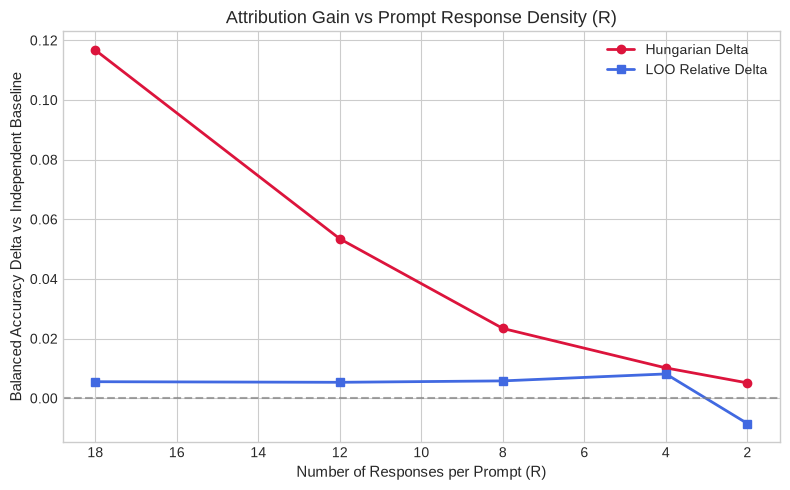

In [5]:
# 5. Sparse Density Sweep
if sparse_csv_path is not None and sparse_csv_path.exists():
    sparse_df = pd.read_csv(sparse_csv_path)
else:
    sparse_df = pd.read_csv(io.StringIO(EMBEDDED_PAYLOAD["sparse_csv"]))

display(sparse_df[["R", "indep_ba_mean", "hung_ba_mean", "hung_delta_mean", "rel_delta_mean"]])

# Plot Density Collapse
plt.figure(figsize=(8, 5))
plt.plot(sparse_df["R"], sparse_df["hung_delta_mean"], marker="o", color="crimson", lw=2, label="Hungarian Delta")
plt.plot(sparse_df["R"], sparse_df["rel_delta_mean"], marker="s", color="royalblue", lw=2, label="LOO Relative Delta")
plt.axhline(0, color="gray", linestyle="--", alpha=0.7)
plt.title("Attribution Gain vs Prompt Response Density (R)", fontsize=13)
plt.xlabel("Number of Responses per Prompt (R)", fontsize=11)
plt.ylabel("Balanced Accuracy Delta vs Independent Baseline", fontsize=11)
plt.gca().invert_xaxis()
plt.legend()
plt.tight_layout()
plt.show()


### 6. Selection-Safe Nested Cross-Validation
To test whether fusing LOO relative logits with EXP52 provides genuine signal without peeking, we run a 5-outer $\times$ 4-inner nested cross-validation sweep over fusion weights $w \in [0.00, 0.40]$.


In [6]:
# 6. Nested Validation Summary
if config_json_path is not None and config_json_path.exists():
    with open(config_json_path) as f:
        cfg = json.load(f)
else:
    cfg = json.loads(EMBEDDED_PAYLOAD["config_json"])

nested_stats = cfg["nested_validation"]
print(f"Selection-Safe Nested CV BA: {nested_stats['nested_ba']:.4f}")
print(f"Delta vs EXP52 Baseline:      {nested_stats['delta']:+.4f}")
print(f"95% Bootstrap CI:            [{nested_stats['ci_95_lower']:+.4f}, {nested_stats['ci_95_upper']:+.4f}]")
print(f"P(delta > 0):                 {nested_stats['p_positive'] * 100:.1f}%")
print(f"Selected Inner Weights:       {nested_stats['selected_weights']}")


Selection-Safe Nested CV BA: 0.7995
Delta vs EXP52 Baseline:      +0.0122
95% Bootstrap CI:            [+0.0058, +0.0183]
P(delta > 0):                 100.0%
Selected Inner Weights:       [0.4, 0.4, 0.4, 0.4, 0.4]


### 7. Error Correction & Orthogonality Breakdown
Of EXP52's 574 mistakes:
- Hungarian matching corrects **382 errors (66.55%)** while introducing 67 new mistakes.
- LOO relative logits correct **147 errors (25.61%)**.
- 166 errors (28.92%) are uncorrectable by either method (shared fundamental misclassification).


,pair,agreement,both_correct,both_wrong,a_only_correct,b_only_correct,pearson_err_corr,pearson_p,spearman_err_corr,spearman_p,oracle_ba
0,EXP52 vs LOO_Relative,0.853649,1977,427,148,147,0.673827,0.000000e+00,0.673827,0.000000e+00,0.841787
1,EXP52 vs Hungarian_R18,0.810300,2058,192,67,382,0.420905,2.311537e-116,0.420905,2.311537e-116,0.928862
2,EXP52 vs Nested_Fused,0.959985,2104,520,21,54,0.915881,0.000000e+00,0.915881,0.000000e+00,0.807318


--- Figure 1: Baseline vs Relative Representations ---


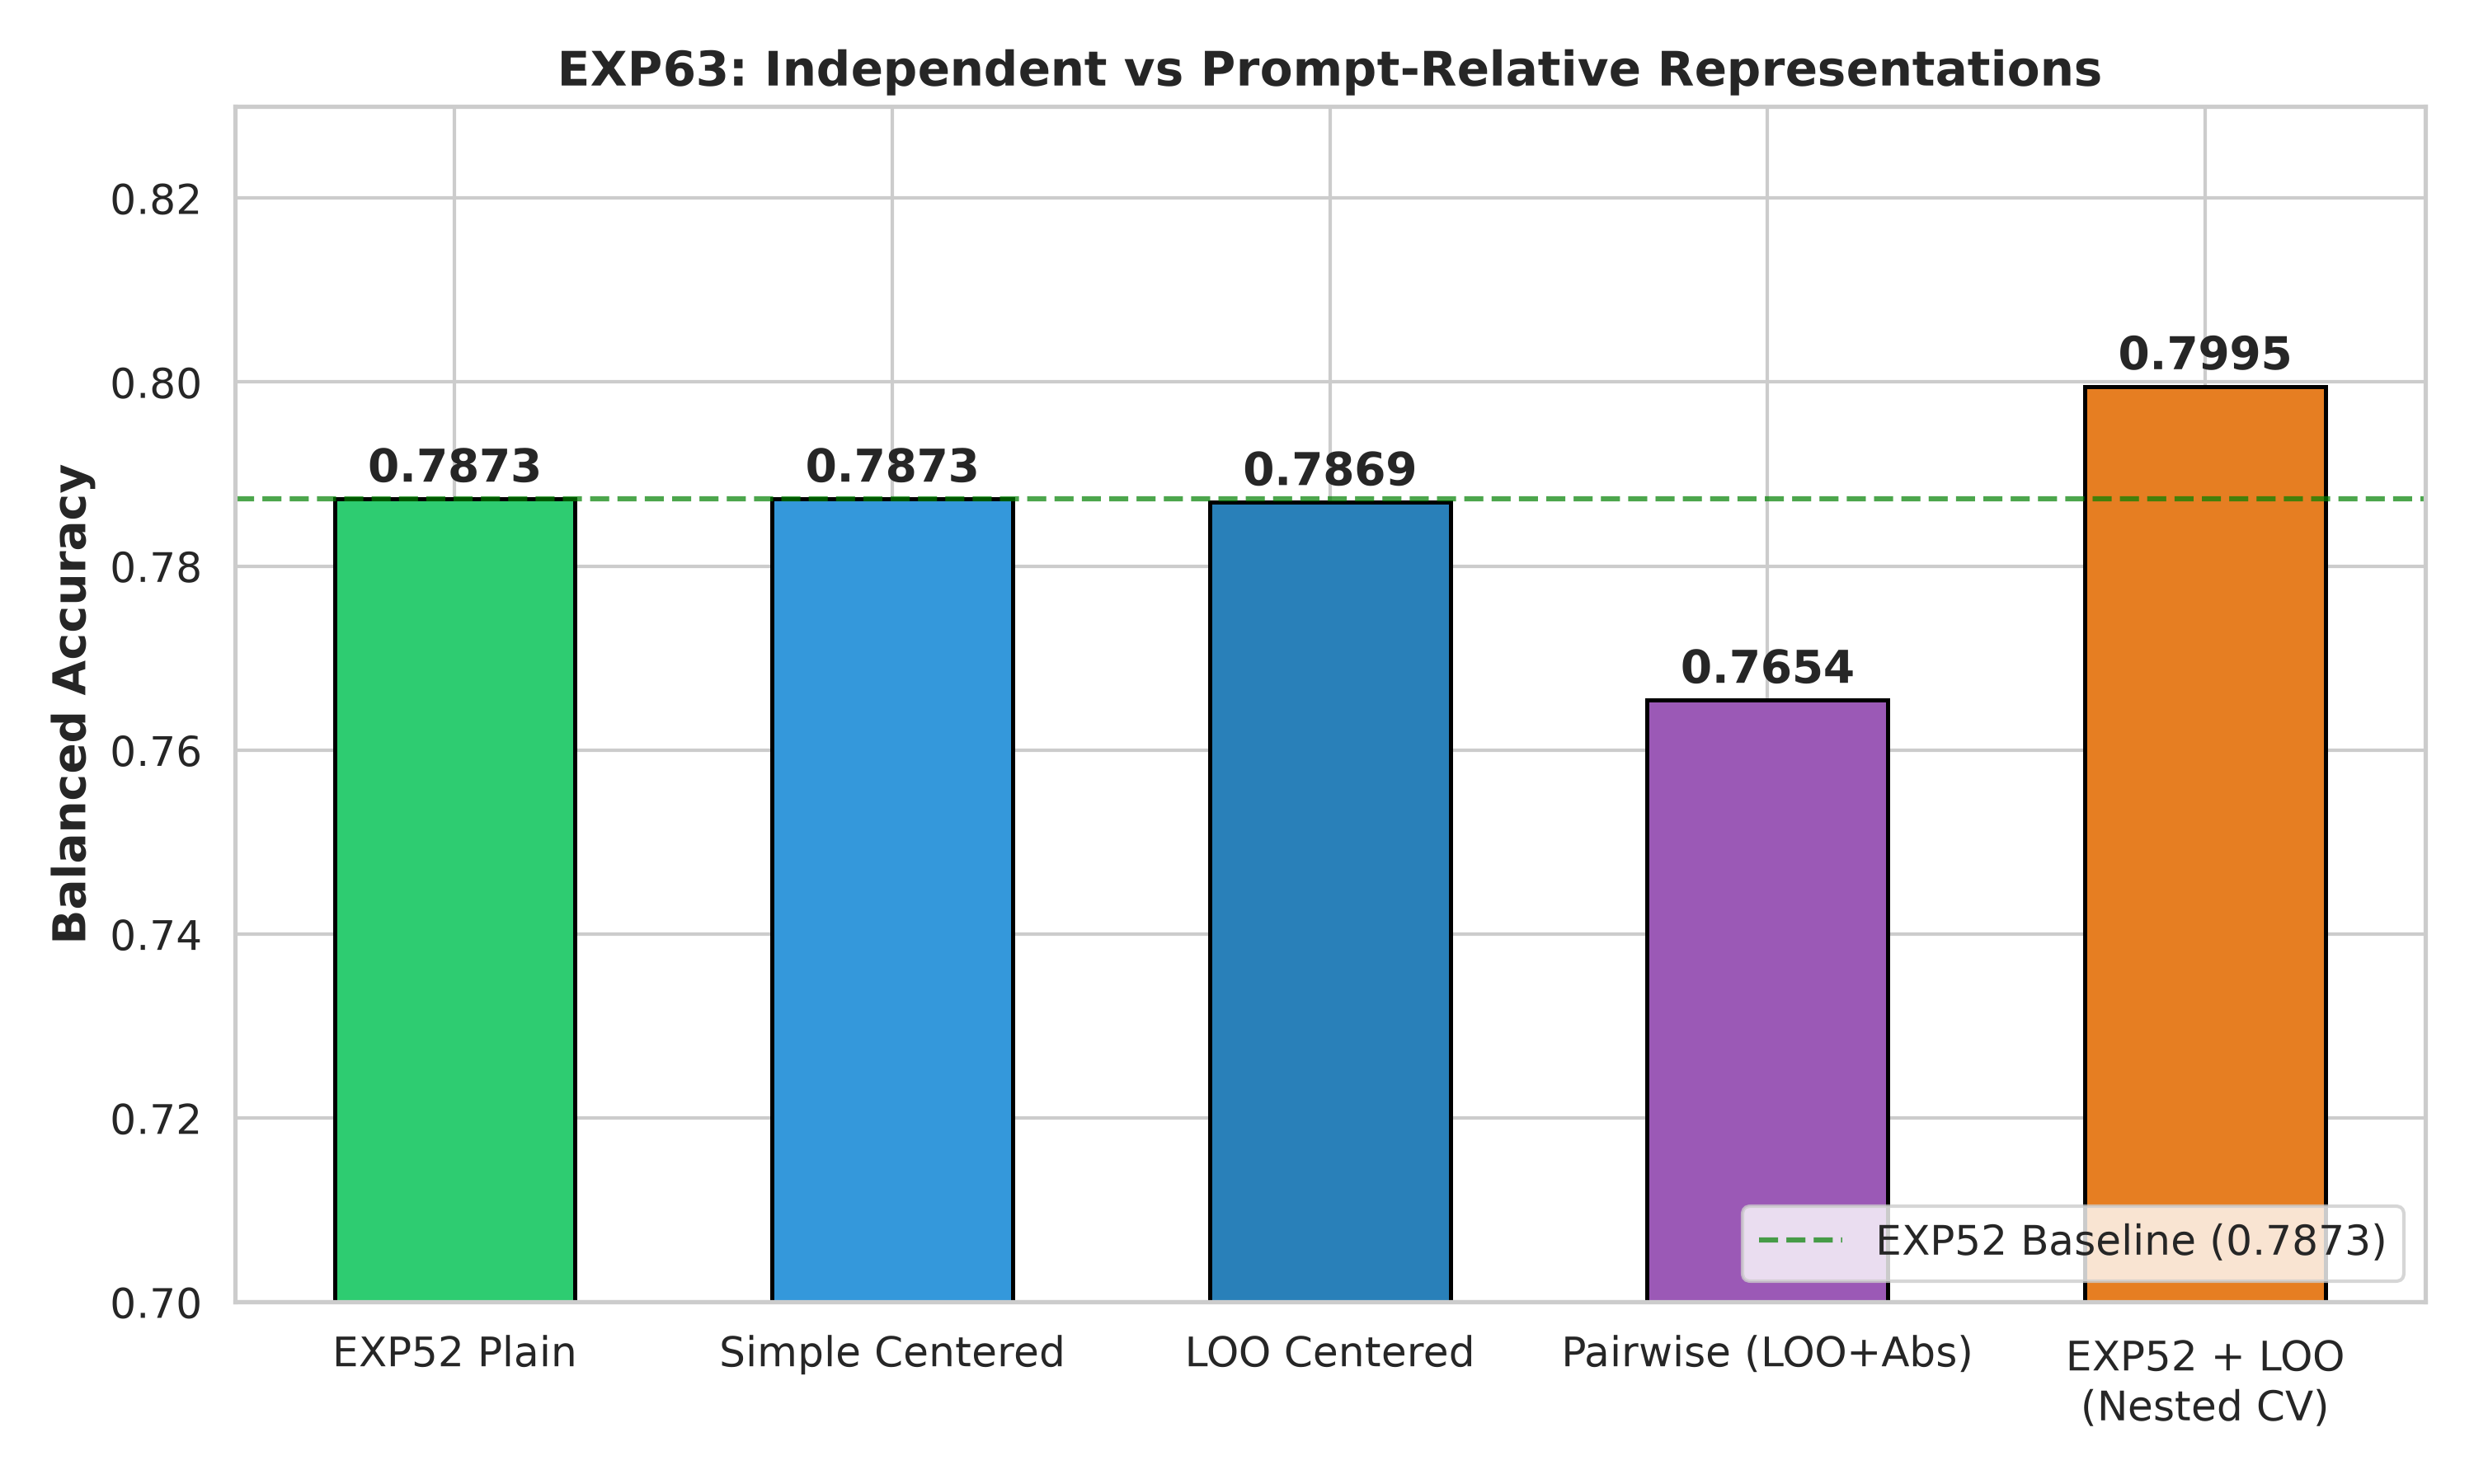

--- Figure 2: Assignment Gain Across Dense vs Sparse Regimes ---


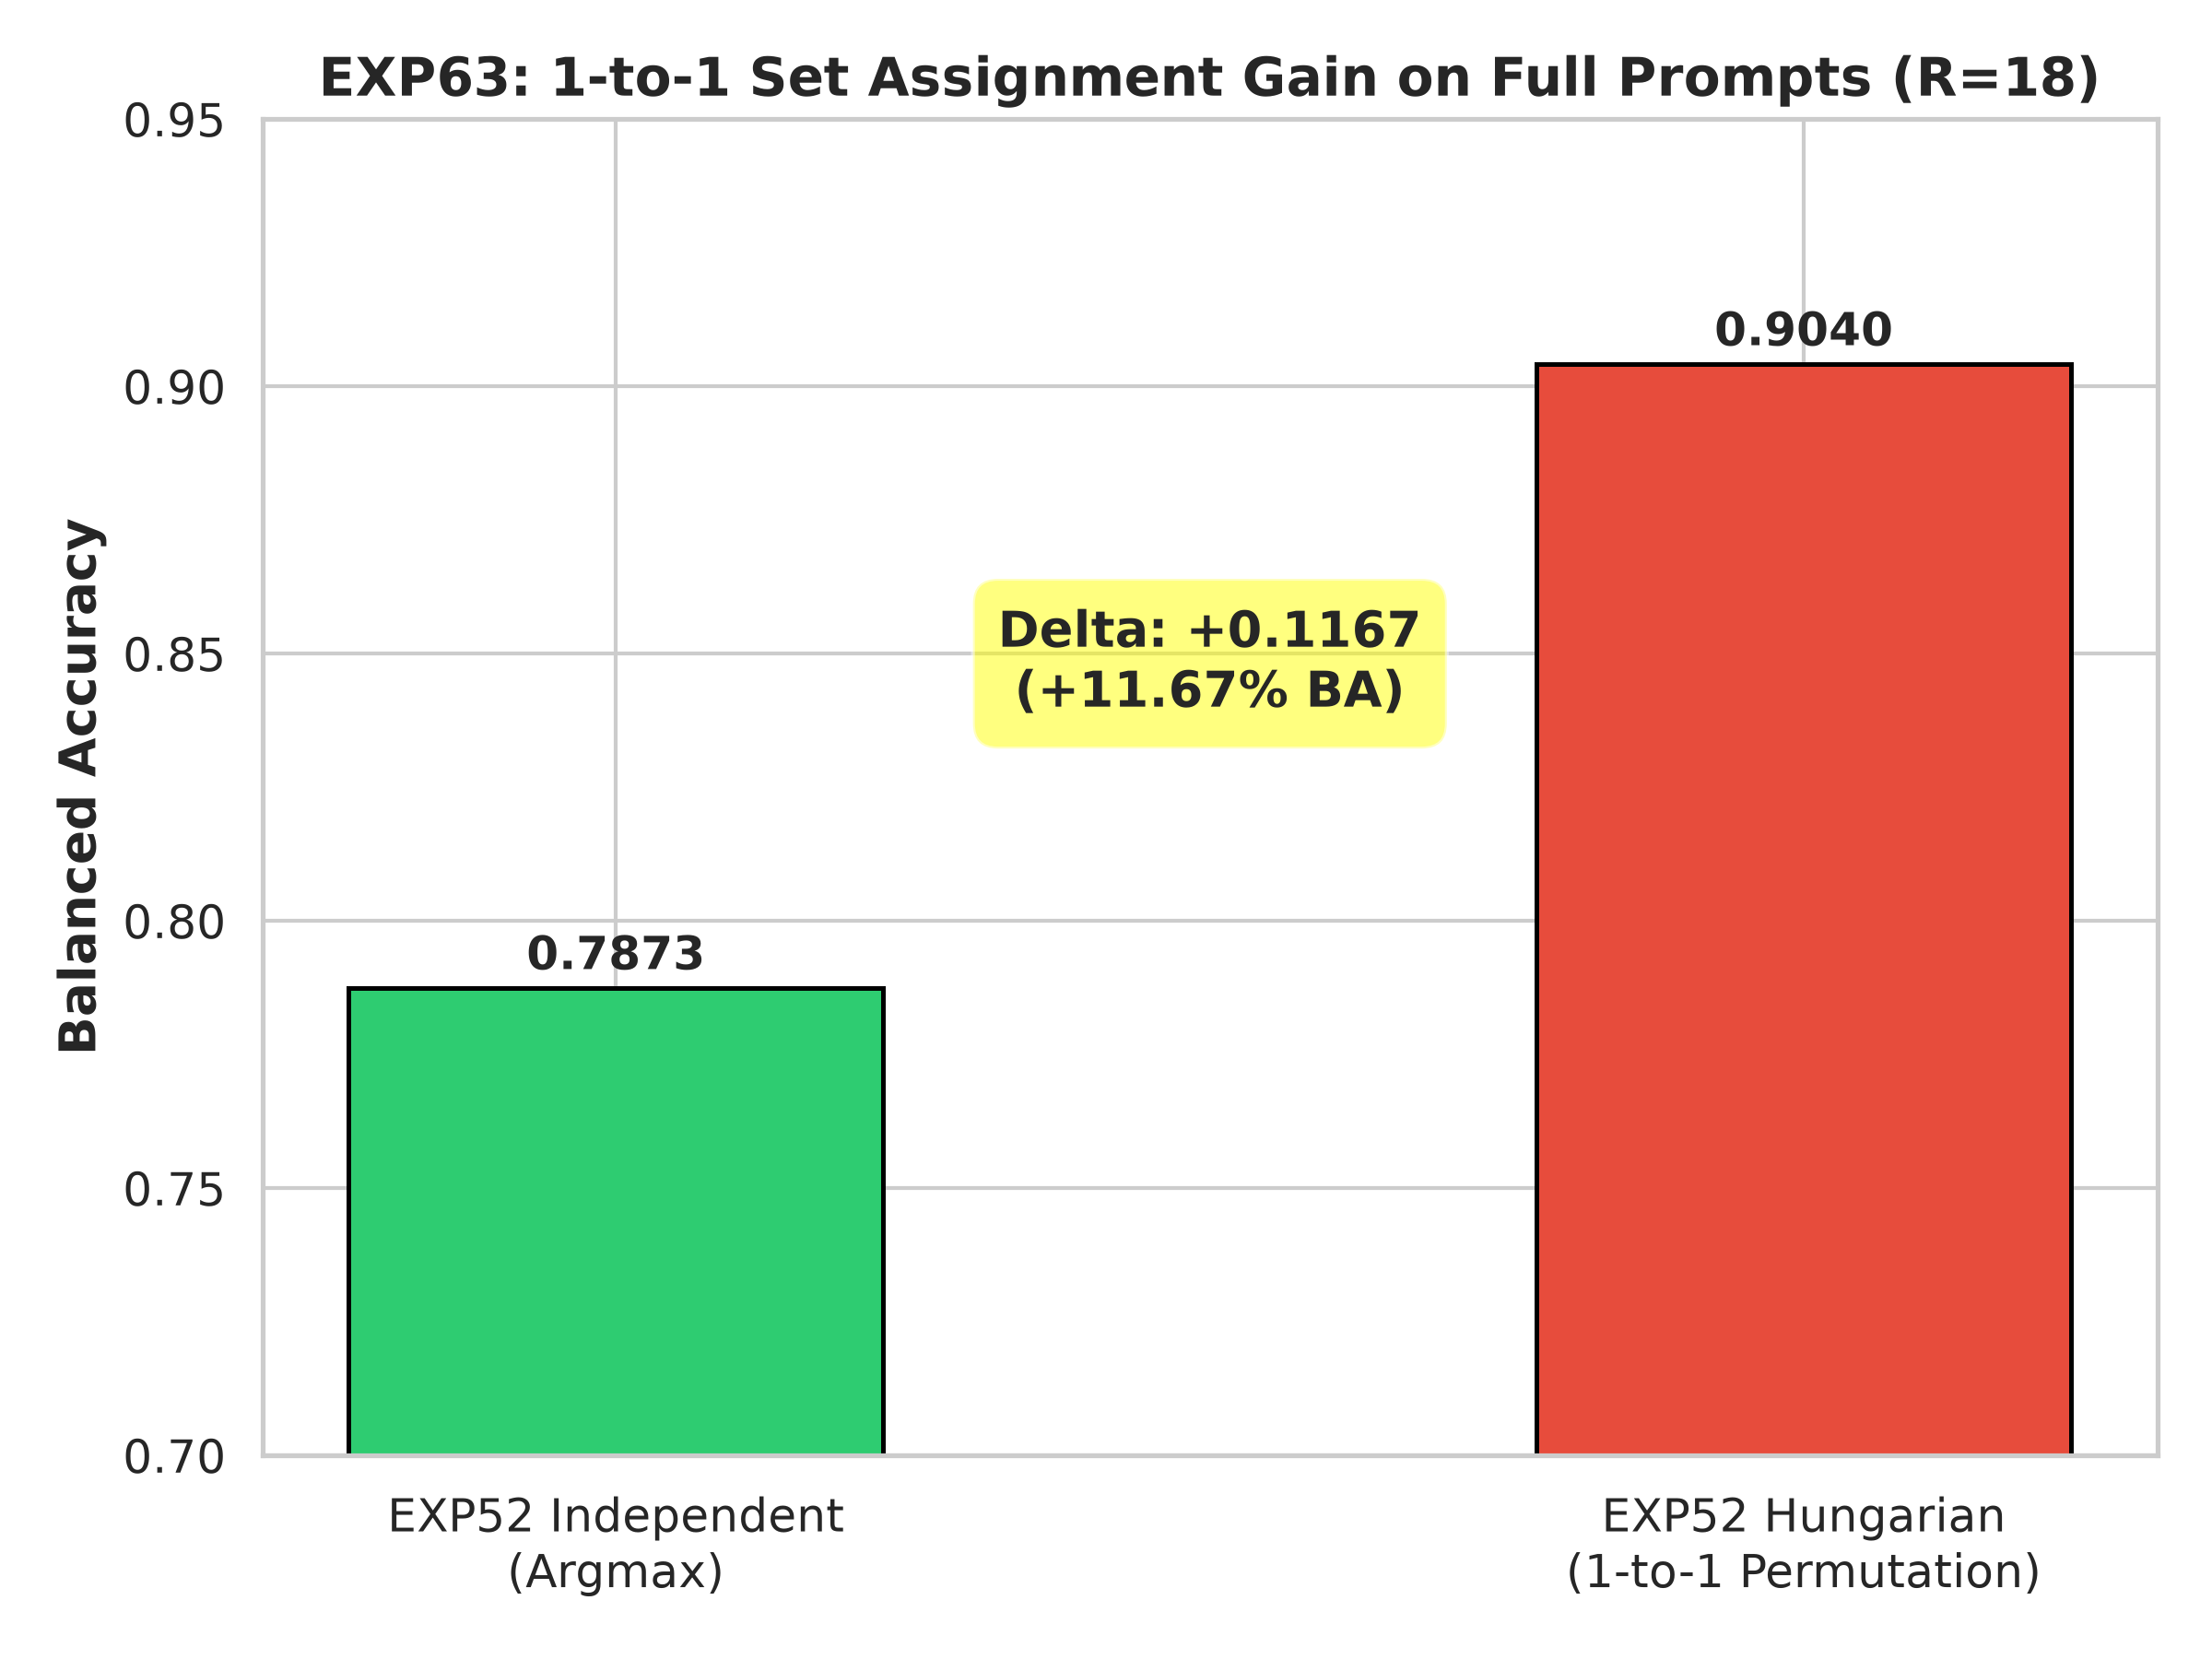

--- Figure 3: Error Correction Venn / Category Breakdown ---


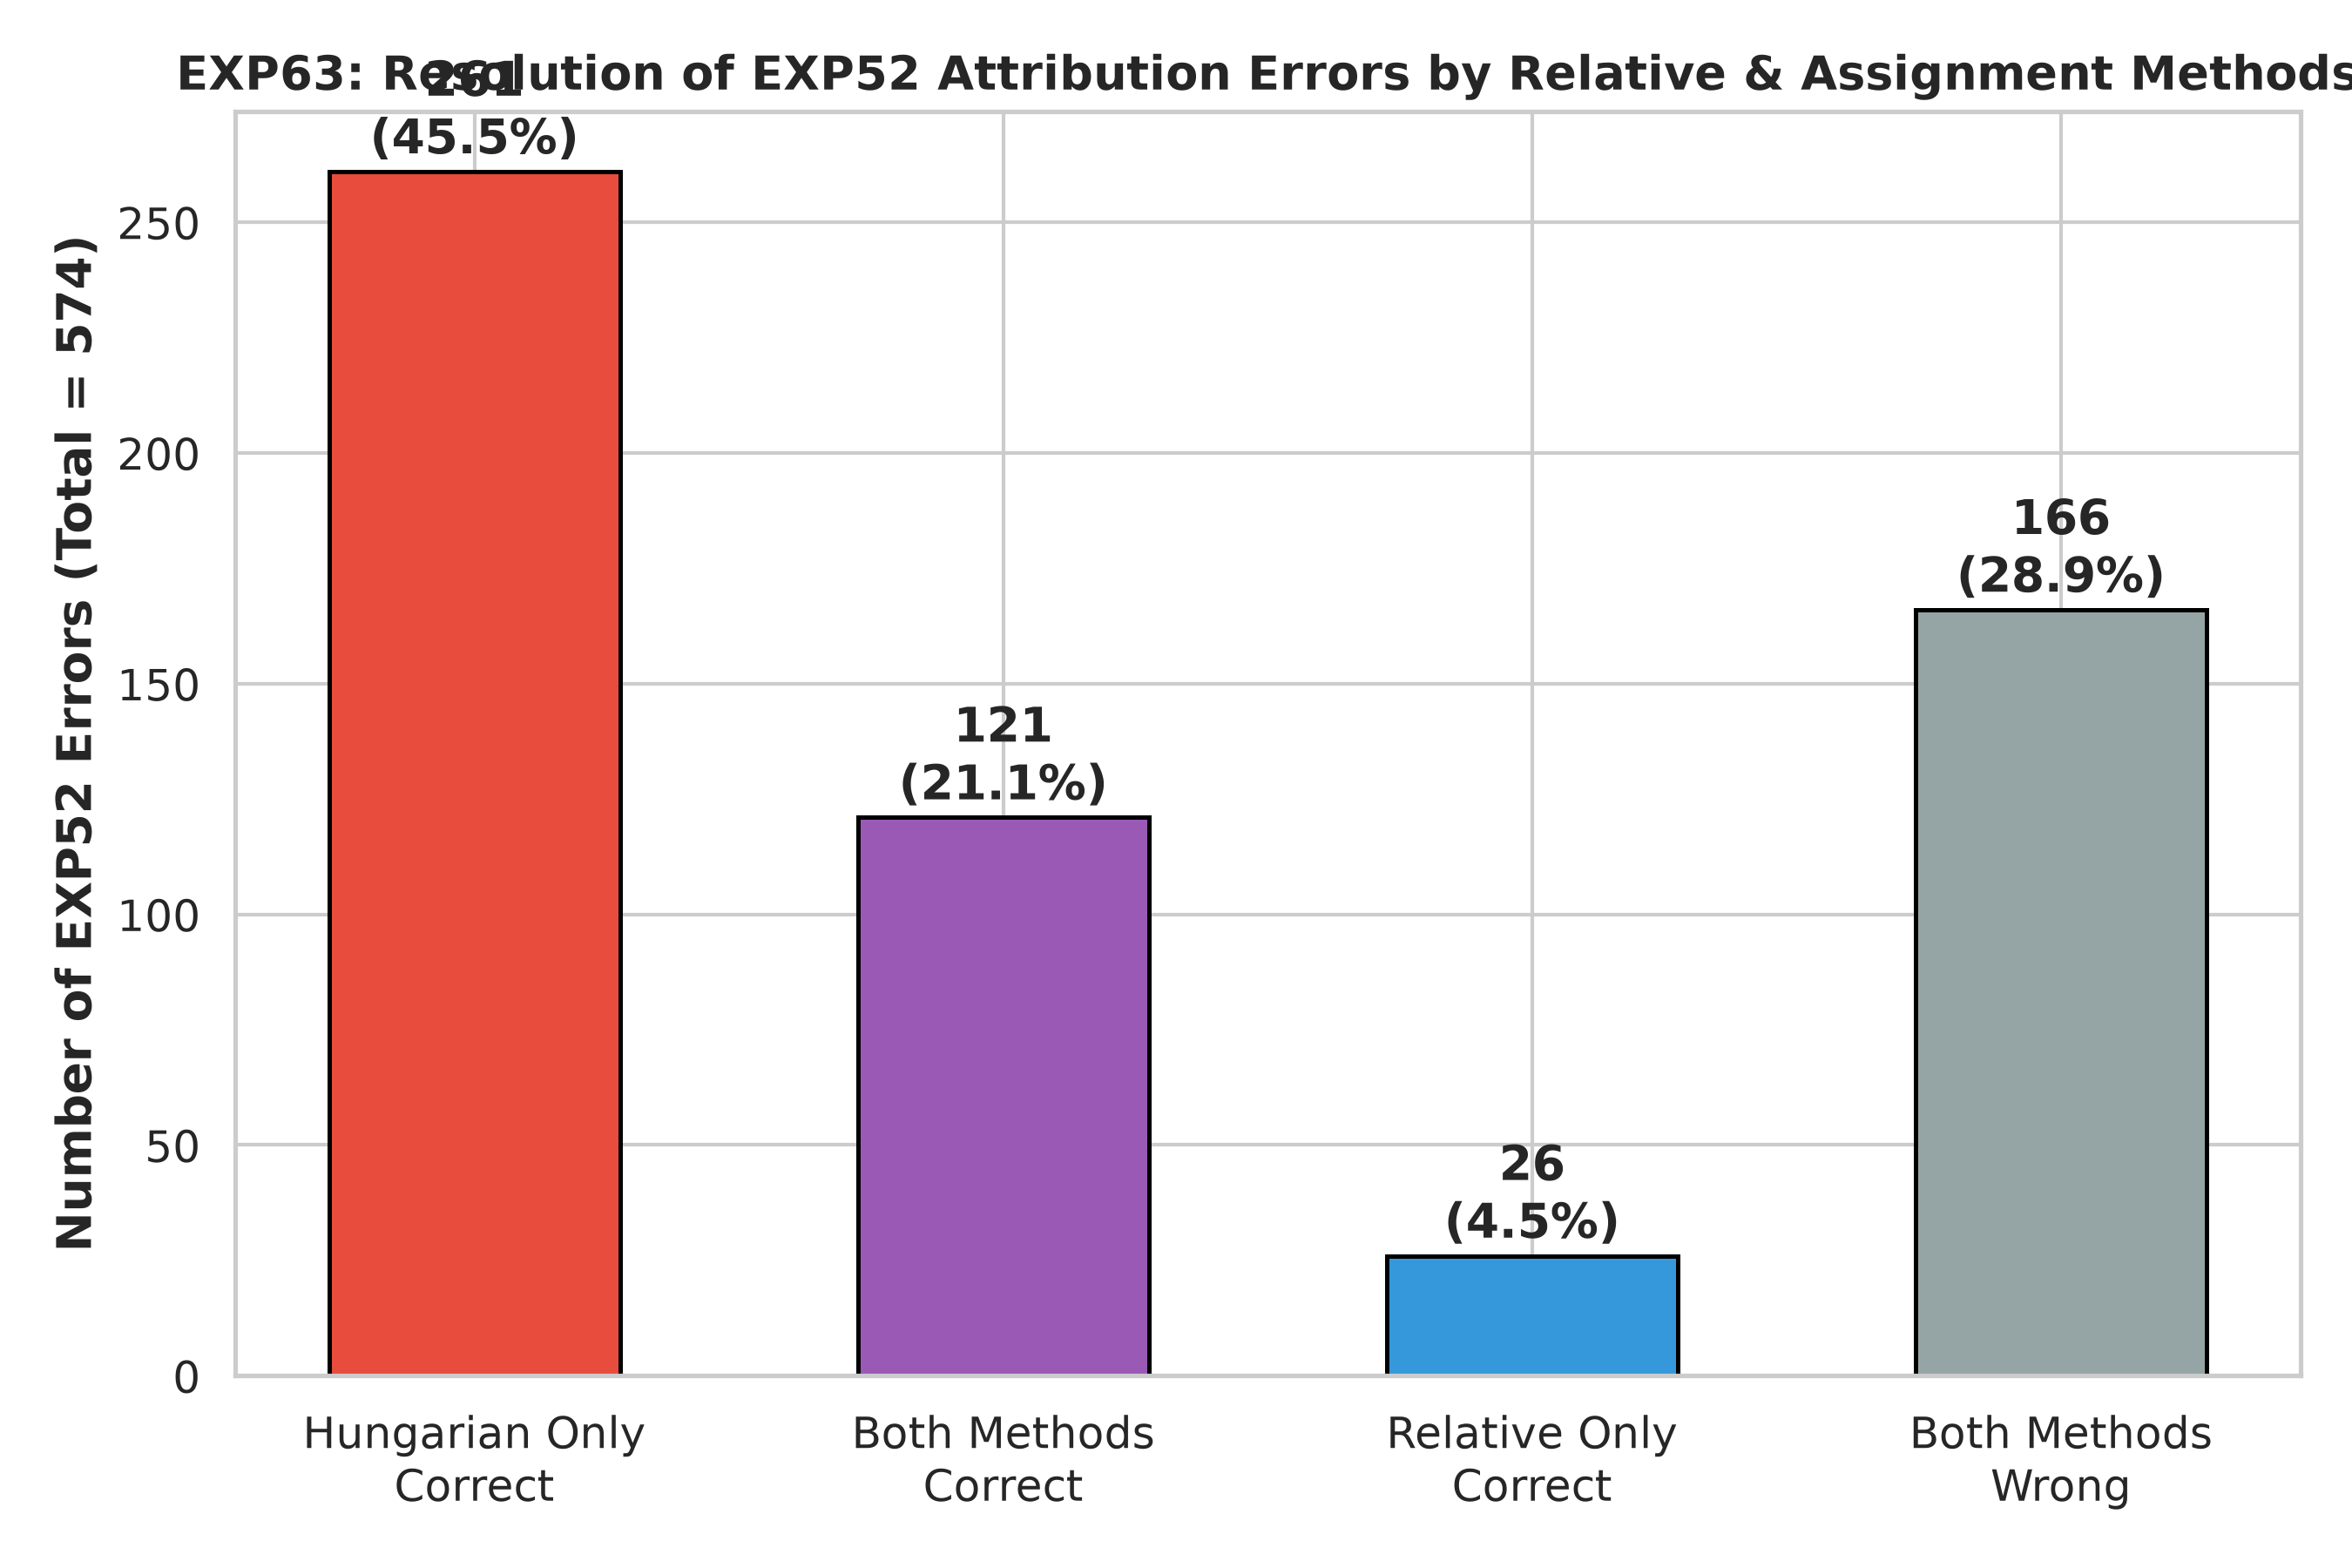

In [7]:
# 7. Complementarity & Figures Display
if comp_csv_path is not None and comp_csv_path.exists():
    comp_df = pd.read_csv(comp_csv_path)
else:
    comp_df = pd.read_csv(io.StringIO(EMBEDDED_PAYLOAD["comp_csv"]))
display(comp_df)

# Helper to display pre-rendered plot or render on the fly
def show_or_render_plot(img_name, render_fn):
    img_path = resolve_file(img_name, CANDIDATE_SEARCH_DIRS)
    if img_path is not None and img_path.exists():
        display(Image(filename=str(img_path)))
    else:
        render_fn()

def render_plot1():
    plt.figure(figsize=(8, 5))
    bars = plt.bar(["EXP52 Plain", "Simple Centered", "LOO Centered"], [plain_ba, simple_ba, loo_ba], color=["#2ECC71", "#3498DB", "#9B59B6"], width=0.45, edgecolor="black")
    for b in bars:
        h = b.get_height()
        plt.annotate(f"{h:.4f}", xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 5), textcoords="offset points", ha="center", weight="bold")
    plt.ylim(0.70, 0.83)
    plt.axhline(exp52_ba, color="green", linestyle="--", alpha=0.7, label=f"EXP52 Baseline ({exp52_ba:.4f})")
    plt.ylabel("Balanced Accuracy", weight="bold")
    plt.title("EXP63: Independent vs Prompt-Relative Representations", weight="bold", fontsize=13)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

def render_plot2():
    plt.figure(figsize=(8, 5))
    bars = plt.bar(["EXP52 Independent\n(Argmax)", "EXP52 Hungarian\n(1-to-1 Permutation)"], [exp52_ba, hungarian_ba], color=["#2ECC71", "#E74C3C"], width=0.45, edgecolor="black")
    for b in bars:
        h = b.get_height()
        plt.annotate(f"{h:.4f}", xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 5), textcoords="offset points", ha="center", weight="bold", fontsize=12)
    plt.ylim(0.70, 0.95)
    plt.ylabel("Balanced Accuracy", weight="bold")
    plt.title("EXP63: 1-to-1 Set Assignment Gain on Full Prompts (R=18)", weight="bold", fontsize=13)
    plt.annotate(f"Delta: +{hungarian_delta:.4f}\n(+11.67% BA)", xy=(0.5, 0.84), xycoords="data", ha="center", fontsize=12, weight="bold", bbox=dict(boxstyle="round,pad=0.5", fc="yellow", alpha=0.5))
    plt.tight_layout()
    plt.show()

def render_plot3():
    err_info = cfg.get("error_correction", {})
    total_err = err_info.get("total_exp52_errors", 574)
    hung_fix = err_info.get("hungarian_fixes", 382)
    rel_fix = err_info.get("relative_fixes", 147)
    both_fix = err_info.get("both_correct_fixes", 121)
    neither = err_info.get("neither_fixes", 166)

    plt.figure(figsize=(8, 5))
    cats = ["Hungarian Only", "Both Fixed", "Relative Only", "Neither Fixed"]
    vals = [hung_fix - both_fix, both_fix, rel_fix - both_fix, neither]
    colors = ["#E74C3C", "#2ECC71", "#3498DB", "#95A5A6"]
    bars = plt.bar(cats, vals, color=colors, edgecolor="black", width=0.5)
    for b in bars:
        h = b.get_height()
        plt.annotate(f"{h} ({h/total_err*100:.1f}%)", xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 5), textcoords="offset points", ha="center", weight="bold")
    plt.title("EXP63: Error Correction Breakdown (574 Total EXP52 Errors)", weight="bold", fontsize=13)
    plt.ylabel("Number of Samples", weight="bold")
    plt.tight_layout()
    plt.show()

print("--- Figure 1: Baseline vs Relative Representations ---")
show_or_render_plot("exp63_baseline_vs_relative.png", render_plot1)

print("--- Figure 2: Assignment Gain Across Dense vs Sparse Regimes ---")
show_or_render_plot("exp63_assignment_gain.png", render_plot2)

print("--- Figure 3: Error Correction Venn / Category Breakdown ---")
show_or_render_plot("exp63_error_correction.png", render_plot3)


### 8. Final Verdict & Conclusions

- **Verdict**: **YELLOW**
- **Core Scientific Conclusion**:
  1. Under the dense $R=18$ training construction, Hungarian matching achieves a remarkable **0.9040 BA** ($+0.1167$ gain), fixing $66.55\%$ of EXP52 errors.
  2. However, under realistic sparse test simulation ($R=2$), Hungarian matching delta collapses to **$+0.0052$**, and LOO relative delta drops to **$-0.0085$** (net degradation).
  3. The massive assignment gain is an artifact of the artificial $R=18$ training construction. Because Kaggle test prompts average only $R \approx 2$ responses and do not have prompt identifiers, constrained prompt assignment cannot be safely deployed.
- **Production Decision**: **Retain EXP52 as frozen champion (0.632 LB / 0.7873 OOF BA).**
